# Insurance charges regression

**BM04BIM Big Data Management and Analytics, 2026-27, Assignment 2**

The dataset `insurance.csv` holds demographic and lifestyle information and the yearly medical charges of a sample of insured people in the US.
This notebook answers the exploratory questions (Q1-Q2), the linear regression questions (Q3-Q8), the logistic regression questions (Q9-Q12) and the decision tree questions (Q13-Q16).
Run it top to bottom on a fresh kernel.

## Setup

The dataset must be in `data/insurance.csv`, in the folder above the one containing this notebook. If it is stored somewhere else, change `DATA_PATH`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

np.random.seed(42)

DATA_PATH = Path("../data/insurance.csv")
IMAGES_DIR = Path("../Images")
IMAGES_DIR.mkdir(exist_ok=True)

PREDICTORS = ["age", "gender", "bmi", "children", "smoker", "region"]
NUMERICAL_COLUMNS = ["age", "bmi", "children", "charges"]
# Right-hand side shared by the regression models; C() marks categorical variables, whose
# first category in alphabetical order becomes the reference level
FORMULA_PREDICTORS = "age + C(gender) + bmi + children + C(smoker) + C(region)"

In [2]:
def significance_level(p_value):
    """Return the strictest of the 0.01, 0.05 and 0.1 levels at which a p-value is significant.

    Args:
        p_value: p-value of a coefficient test.

    Returns:
        "0.01", "0.05" or "0.1", or "not significant" when the p-value is 0.1 or higher.
    """
    for level in [0.01, 0.05, 0.1]:
        if p_value < level:
            return str(level)
    return "not significant"


def coefficient_table(model):
    """Collect the coefficients, p-values and significance levels of a fitted statsmodels model.

    Args:
        model: fitted statsmodels regression results.

    Returns:
        DataFrame with one row per coefficient.
    """
    table = pd.DataFrame({"coefficient": model.params, "p_value": model.pvalues})
    table["significant_at"] = table["p_value"].apply(significance_level)
    return table.round(4)


def plot_residual_histogram(residuals, title, xlabel, color, file_name):
    """Plot a histogram of model residuals and save it to IMAGES_DIR.

    Args:
        residuals: residuals of a fitted model.
        title: plot title.
        xlabel: label of the x axis.
        color: bar colour.
        file_name: name of the PNG file to save.
    """
    plt.figure(figsize=(7, 4.5))
    plt.hist(residuals, bins=40, color=color, edgecolor="white")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.savefig(IMAGES_DIR / file_name, dpi=150)
    plt.show()


def plot_residuals_vs_fitted(fitted, residuals, title, xlabel, ylabel, color, file_name):
    """Plot residuals against fitted values with a zero line and save it to IMAGES_DIR.

    Args:
        fitted: fitted values of the model.
        residuals: residuals of the model.
        title: plot title.
        xlabel: label of the x axis.
        ylabel: label of the y axis.
        color: marker colour.
        file_name: name of the PNG file to save.
    """
    plt.figure(figsize=(7, 4.5))
    plt.scatter(fitted, residuals, s=10, alpha=0.5, color=color)
    plt.axhline(0, color="black", linewidth=1)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(IMAGES_DIR / file_name, dpi=150)
    plt.show()

In [3]:
insurance = pd.read_csv(DATA_PATH)
print(f"insurance: {insurance.shape[0]} rows, {insurance.shape[1]} columns")
print(f"Missing values: {insurance.isna().sum().sum()}")
insurance.head()

insurance: 1337 rows, 7 columns
Missing values: 0


,age,gender,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# The five new people used for the predictions in Q8, Q12 and Q16
new_people = pd.DataFrame({
    "age": [25, 45, 32, 54, 29],
    "gender": ["male", "female", "male", "female", "female"],
    "bmi": [28.0, 35.2, 30.5, 24.7, 22.8],
    "children": [1, 3, 0, 2, 1],
    "smoker": ["no", "yes", "no", "yes", "yes"],
    "region": ["northeast", "southeast", "northwest", "southwest", "southeast"]
})
new_people

,age,gender,bmi,children,smoker,region
0,25,male,28.0,1,no,northeast
1,45,female,35.2,3,yes,southeast
2,32,male,30.5,0,no,northwest
3,54,female,24.7,2,yes,southwest
4,29,female,22.8,1,yes,southeast


## Exploratory data analysis

### Q1. Charges of smokers and non-smokers by age group

In [5]:
age_bins = [18, 30, 40, 50, 60, 70]
age_labels = ["[18, 30)", "[30, 40)", "[40, 50)", "[50, 60)", "[60, 70)"]
insurance["age_group"] = pd.cut(insurance["age"], bins=age_bins, labels=age_labels, right=False)

charges_by_group = insurance.pivot_table(
    index="age_group",
    columns="smoker",
    values="charges",
    aggfunc="mean",
    observed=True
)
charges_by_group["difference"] = charges_by_group["yes"] - charges_by_group["no"]
charges_by_group.round(2)

smoker,no,yes,difference
age_group,,,
"[18, 30)",4426.99,27518.04,23091.05
"[30, 40)",6337.36,30271.25,23933.88
"[40, 50)",9183.34,32654.72,23471.38
"[50, 60)",12749.34,37508.75,24759.41
"[60, 70)",15232.71,40630.70,25397.99


In [6]:
largest_gap_group = charges_by_group["difference"].idxmax()
largest_gap = charges_by_group["difference"].max()
print(f"Largest difference: age group {largest_gap_group}, smokers pay ${largest_gap:,.2f} more on average")

Largest difference: age group [60, 70), smokers pay $25,397.99 more on average


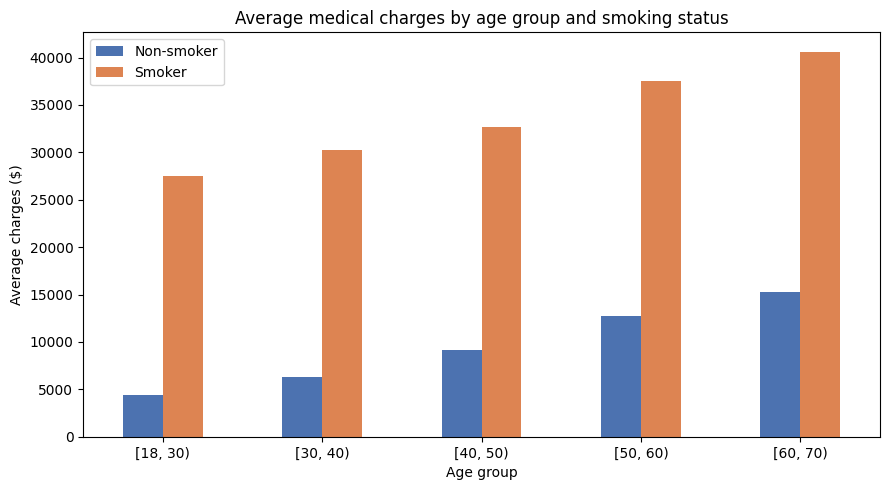

In [7]:
ax = charges_by_group[["no", "yes"]].plot(kind="bar", figsize=(9, 5), color=["#4c72b0", "#dd8452"])
ax.set_title("Average medical charges by age group and smoking status")
ax.set_xlabel("Age group")
ax.set_ylabel("Average charges ($)")
ax.legend(["Non-smoker", "Smoker"])
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "charges_by_age_smoker.png", dpi=150)
plt.show()

### Q2. Correlation matrix of the numerical variables

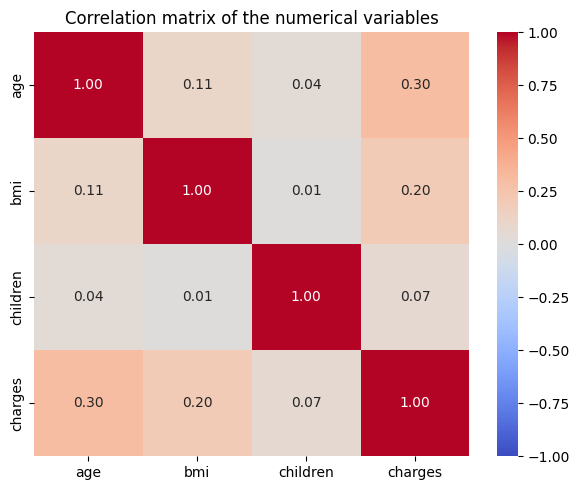

Strongest correlation with charges: age (0.298)


In [8]:
correlation_matrix = insurance[NUMERICAL_COLUMNS].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix of the numerical variables")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

charges_correlation = correlation_matrix["charges"].drop("charges")
strongest_variable = charges_correlation.abs().idxmax()
print(f"Strongest correlation with charges: {strongest_variable} ({charges_correlation[strongest_variable]:.3f})")

## Linear regression

### Q3. Linear regression on charges

The categorical variables enter the model as dummy variables. The reference levels are `female` for gender, `no` for smoker and `northeast` for region.

In [9]:
linear_model = smf.ols(f"charges ~ {FORMULA_PREDICTORS}", data=insurance).fit()
print(linear_model.summary())

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.751
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     500.0
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:07:09   Log-Likelihood:                -13538.
No. Observations:                1337   AIC:                         2.709e+04
Df Residuals:                    1328   BIC:                         2.714e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept              -1.19

In [10]:
coefficient_table(linear_model)

,coefficient,p_value,significant_at
Intercept,-11936.5575,0.0000,0.01
C(gender)[T.male],-129.4815,0.6976,not significant
C(smoker)[T.yes],23847.3288,0.0000,0.01
C(region)[T.northwest],-349.2265,0.4641,not significant
C(region)[T.southeast],-1035.2656,0.0308,0.05
C(region)[T.southwest],-960.0814,0.0448,0.05
age,256.7646,0.0000,0.01
bmi,339.2504,0.0000,0.01
children,474.8205,0.0006,0.01


### Q4. Coefficients of age, gender, bmi and region

The interpretation of each coefficient (holding the other variables fixed) is written in the report; the values are in the table above.

### Q5. Residual checks for the linear model

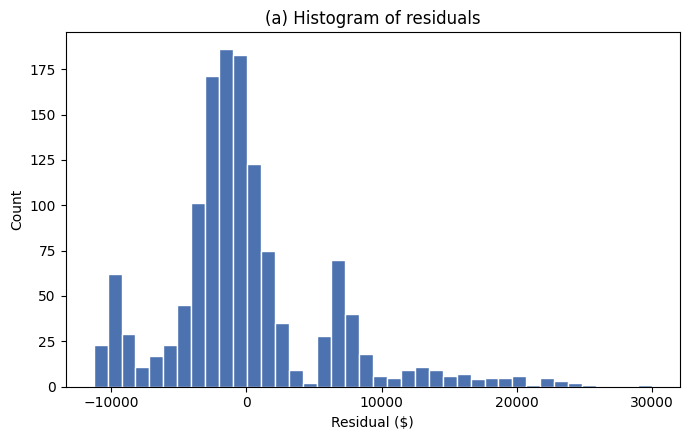

In [11]:
plot_residual_histogram(
    linear_model.resid,
    "(a) Histogram of residuals",
    "Residual ($)",
    "#4c72b0",
    "residuals_linear_histogram.png"
)

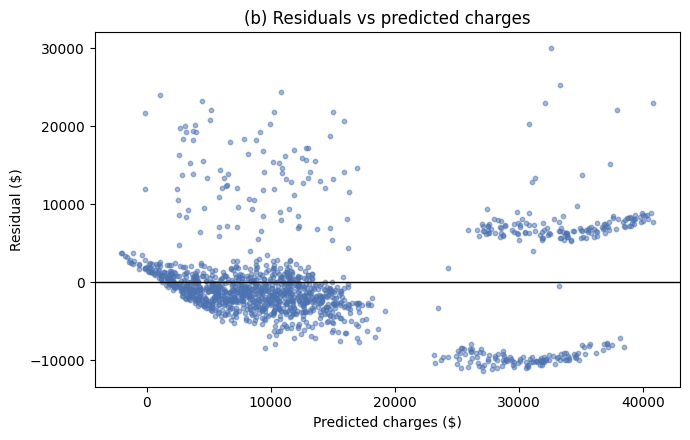

In [12]:
plot_residuals_vs_fitted(
    linear_model.fittedvalues,
    linear_model.resid,
    "(b) Residuals vs predicted charges",
    "Predicted charges ($)",
    "Residual ($)",
    "#4c72b0",
    "residuals_linear_vs_predicted.png"
)

### Q6. Linear regression on log_charges

In [13]:
insurance["log_charges"] = np.log(insurance["charges"])

log_model = smf.ols(f"log_charges ~ {FORMULA_PREDICTORS}", data=insurance).fit()
print(log_model.summary())

                            OLS Regression Results                            
Dep. Variable:            log_charges   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.766
Method:                 Least Squares   F-statistic:                     548.4
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:07:10   Log-Likelihood:                -807.62
No. Observations:                1337   AIC:                             1633.
Df Residuals:                    1328   BIC:                             1680.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  7

In [14]:
# (a) With a log target, a one-year increase in age multiplies charges by exp(coefficient)
age_coefficient = log_model.params["age"]
age_effect = np.exp(age_coefficient) - 1
print(f"Age coefficient: {age_coefficient:.4f}")
print(f"Each extra year of age raises expected charges by {age_effect:.2%}, other variables fixed")

Age coefficient: 0.0345
Each extra year of age raises expected charges by 3.51%, other variables fixed


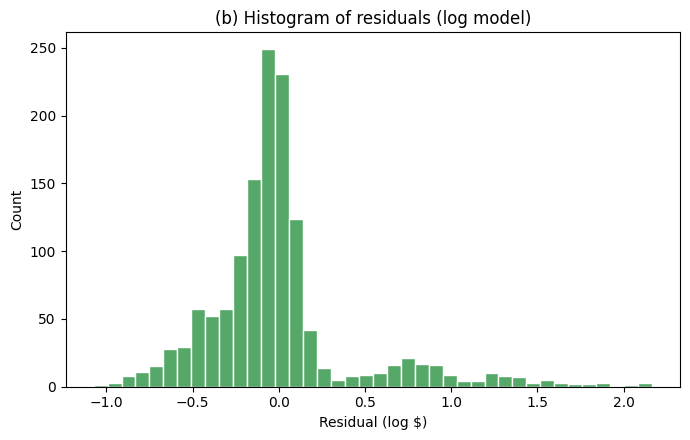

In [15]:
plot_residual_histogram(
    log_model.resid,
    "(b) Histogram of residuals (log model)",
    "Residual (log $)",
    "#55a868",
    "residuals_log_histogram.png"
)

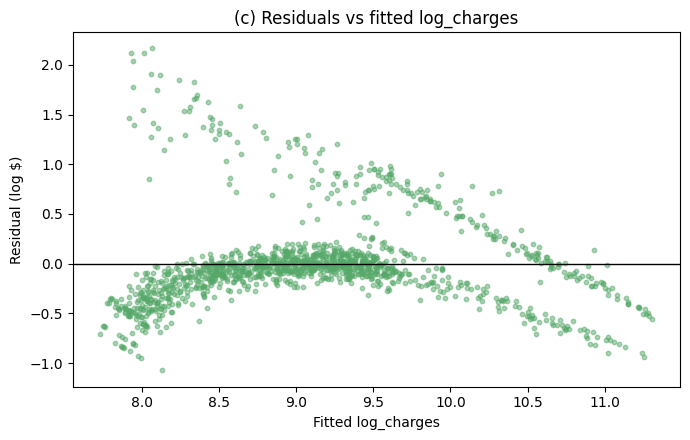

In [16]:
plot_residuals_vs_fitted(
    log_model.fittedvalues,
    log_model.resid,
    "(c) Residuals vs fitted log_charges",
    "Fitted log_charges",
    "Residual (log $)",
    "#55a868",
    "residuals_log_vs_fitted.png"
)

### Q7. Overall fit of the log model

In [17]:
print(f"R-squared: {log_model.rsquared:.4f}")
print(f"Adjusted R-squared: {log_model.rsquared_adj:.4f}")

R-squared: 0.7676
Adjusted R-squared: 0.7662


### Q8. Predicted charges for the five new people

The log model predicts `log_charges`, so the prediction is transformed back to dollars with the exponential.

In [18]:
linear_predictions = new_people.copy()
linear_predictions["predicted_log_charges"] = log_model.predict(new_people)
linear_predictions["predicted_charges"] = np.exp(linear_predictions["predicted_log_charges"])
linear_predictions.round(2)

,age,gender,bmi,children,smoker,region,predicted_log_charges,predicted_charges
0,25,male,28.0,1,no,northeast,8.30,4012.49
1,45,female,35.2,3,yes,southeast,10.76,47029.58
2,32,male,30.5,0,no,northwest,8.41,4486.61
3,54,female,24.7,2,yes,southwest,10.86,51816.93
4,29,female,22.8,1,yes,southeast,9.84,18706.97


## Logistic regression

### Q9. Binary target: charges above the mean

In [19]:
mean_charges = insurance["charges"].mean()
insurance["binary_charges"] = (insurance["charges"] > mean_charges).astype(int)

print(f"Mean charges: ${mean_charges:,.2f}")
binary_shares = insurance["binary_charges"].value_counts(normalize=True)
binary_shares = binary_shares.sort_index()
(binary_shares * 100).round(2)

Mean charges: $13,279.12


binary_charges
0    68.59
1    31.41
Name: proportion, dtype: float64

### Q10. Logistic regression on binary_charges

In [20]:
logistic_model = smf.logit(f"binary_charges ~ {FORMULA_PREDICTORS}", data=insurance).fit()
print(logistic_model.summary())

Optimization terminated successfully.
         Current function value: 0.283007
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:         binary_charges   No. Observations:                 1337
Model:                          Logit   Df Residuals:                     1328
Method:                           MLE   Df Model:                            8
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                  0.5453
Time:                        15:07:12   Log-Likelihood:                -378.38
converged:                       True   LL-Null:                       -832.11
Covariance Type:            nonrobust   LLR p-value:                1.391e-190
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -5.3096      0.639     -8.309      0.000      -6.562     

In [21]:
logistic_table = coefficient_table(logistic_model)
# exp(coefficient) is the odds ratio: the factor by which the odds of above-mean charges change
logistic_table["odds_ratio"] = np.exp(logistic_model.params).round(4)
logistic_table

,coefficient,p_value,significant_at,odds_ratio
Intercept,-5.3096,0.0000,0.01,0.0049
C(gender)[T.male],-0.2743,0.1462,not significant,0.7601
C(smoker)[T.yes],8.3960,0.0000,0.01,4429.3360
C(region)[T.northwest],-0.1571,0.5406,not significant,0.8547
C(region)[T.southeast],-0.2034,0.4385,not significant,0.8159
C(region)[T.southwest],-0.6648,0.0159,0.05,0.5144
age,0.0712,0.0000,0.01,1.0738
bmi,0.0183,0.2632,not significant,1.0184
children,0.1180,0.1191,not significant,1.1253


### Q11. Coefficients of age, gender, bmi and region

The interpretation, in terms of log-odds and odds ratios, is written in the report; the values are in the table above. The reference region is again `northeast`.

### Q12. Predicted binary_charges for the five new people

In [22]:
logistic_predictions = new_people.copy()
logistic_predictions["probability"] = logistic_model.predict(new_people)
logistic_predictions["predicted_binary_charges"] = (logistic_predictions["probability"] >= 0.5).astype(int)
logistic_predictions.round(4)

,age,gender,bmi,children,smoker,region,probability,predicted_binary_charges
0,25,male,28.0,1,no,northeast,0.0401,0
1,45,female,35.2,3,yes,southeast,0.9992,1
2,32,male,30.5,0,no,northwest,0.0519,0
3,54,female,24.7,2,yes,southwest,0.9990,1
4,29,female,22.8,1,yes,southeast,0.9959,1


## Decision tree

### Q13. Three-class target: low, medium and high charges

In [23]:
q1 = insurance["charges"].quantile(0.25)
q3 = insurance["charges"].quantile(0.75)
insurance["multiclass_charges"] = pd.cut(
    insurance["charges"],
    bins=[-np.inf, q1, q3, np.inf],
    labels=["low", "medium", "high"]
)

print(f"q1: ${q1:,.2f}, q3: ${q3:,.2f}")
multiclass_shares = insurance["multiclass_charges"].value_counts(normalize=True)
multiclass_shares = multiclass_shares.reindex(["low", "medium", "high"])
(multiclass_shares * 100).round(2)

q1: $4,746.34, q3: $16,657.72


multiclass_charges
low       25.06
medium    49.96
high      24.98
Name: proportion, dtype: float64

### Q14. Decision tree with maximum depth 4

scikit-learn needs numerical inputs, so the categorical predictors are turned into dummy variables with the same reference levels as the regressions.

In [24]:
tree_features = pd.get_dummies(insurance[PREDICTORS], drop_first=True, dtype=int)
tree_target = insurance["multiclass_charges"].astype(str)

tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_model.fit(tree_features, tree_target)

print(f"Features: {list(tree_features.columns)}")
print(f"Number of leaf nodes: {tree_model.get_n_leaves()}")

Features: ['age', 'bmi', 'children', 'gender_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Number of leaf nodes: 15


### Q15. Plot of the decision tree

The text version below lists every path from the root to a leaf, to pick one for the report.

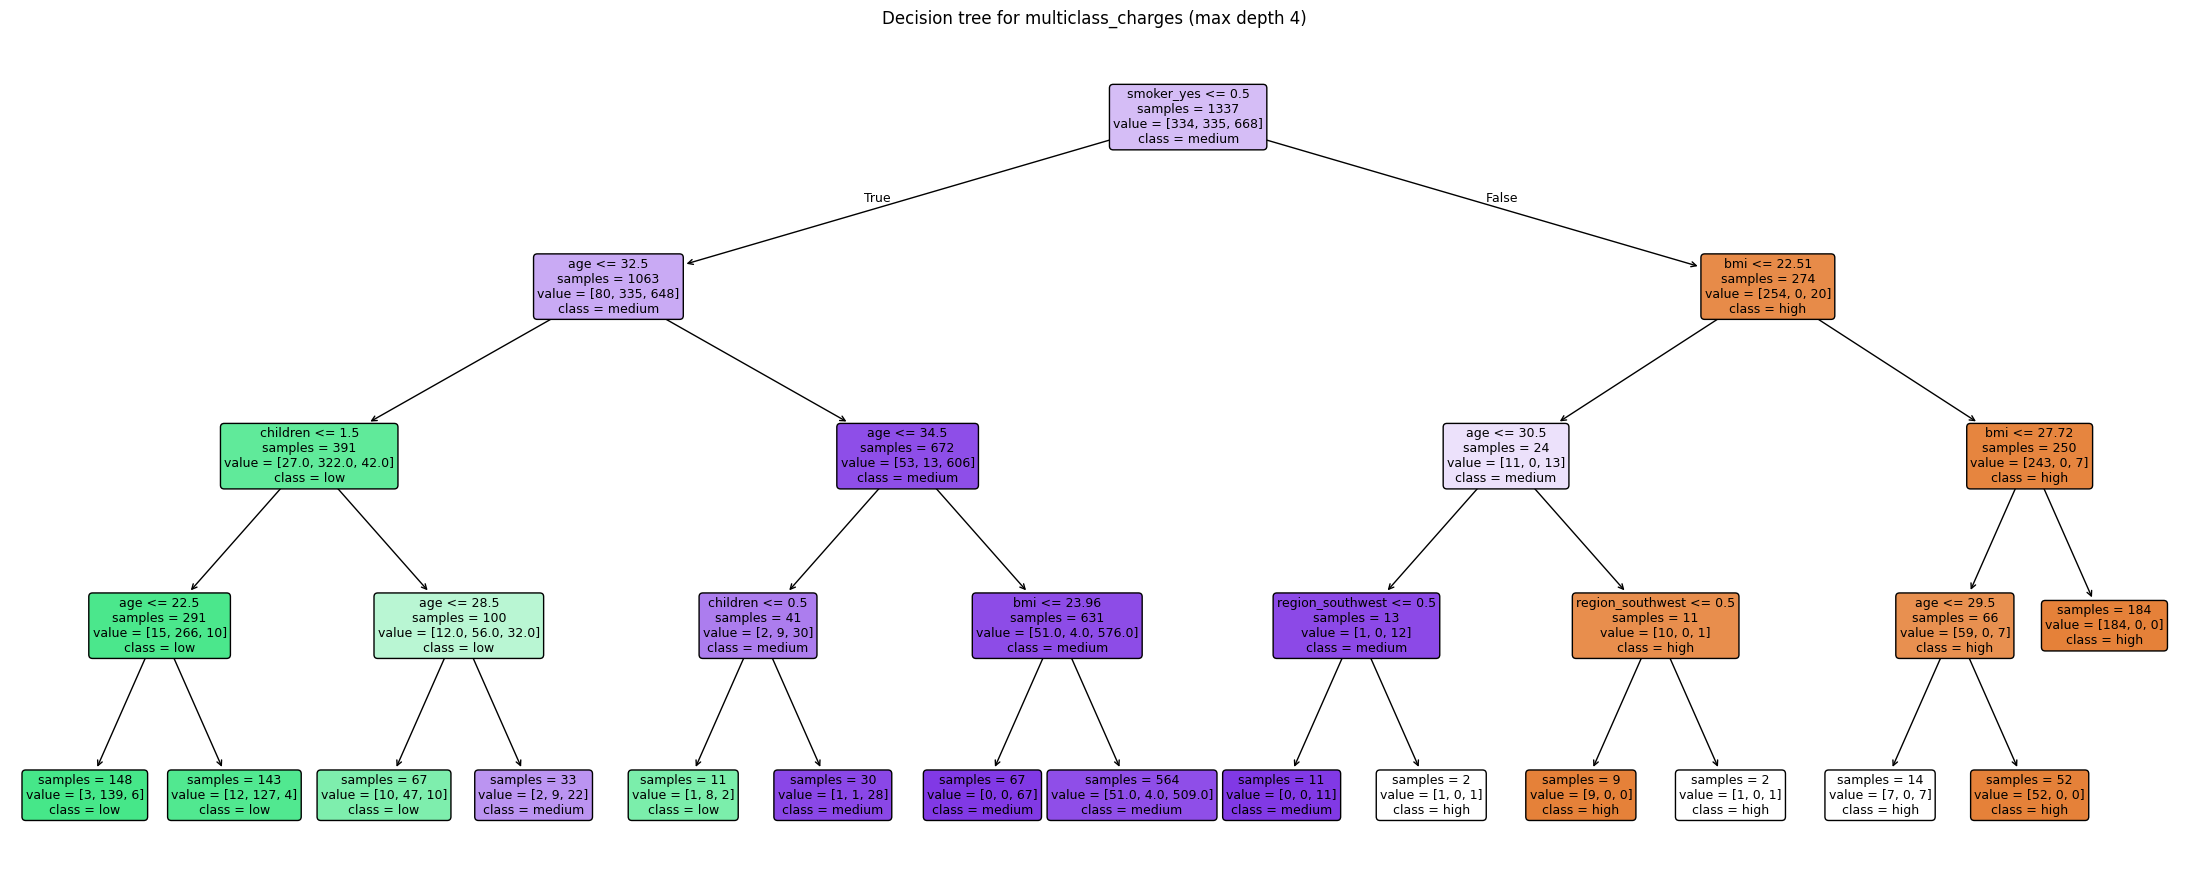

In [25]:
plt.figure(figsize=(22, 9))
plot_tree(
    tree_model,
    feature_names=list(tree_features.columns),
    class_names=list(tree_model.classes_),
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=9
)
plt.title("Decision tree for multiclass_charges (max depth 4)")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "decision_tree.png", dpi=200)
plt.show()

In [26]:
print(export_text(tree_model, feature_names=list(tree_features.columns)))

|--- smoker_yes <= 0.50
|   |--- age <= 32.50
|   |   |--- children <= 1.50
|   |   |   |--- age <= 22.50
|   |   |   |   |--- class: low
|   |   |   |--- age >  22.50
|   |   |   |   |--- class: low
|   |   |--- children >  1.50
|   |   |   |--- age <= 28.50
|   |   |   |   |--- class: low
|   |   |   |--- age >  28.50
|   |   |   |   |--- class: medium
|   |--- age >  32.50
|   |   |--- age <= 34.50
|   |   |   |--- children <= 0.50
|   |   |   |   |--- class: low
|   |   |   |--- children >  0.50
|   |   |   |   |--- class: medium
|   |   |--- age >  34.50
|   |   |   |--- bmi <= 23.96
|   |   |   |   |--- class: medium
|   |   |   |--- bmi >  23.96
|   |   |   |   |--- class: medium
|--- smoker_yes >  0.50
|   |--- bmi <= 22.51
|   |   |--- age <= 30.50
|   |   |   |--- region_southwest <= 0.50
|   |   |   |   |--- class: medium
|   |   |   |--- region_southwest >  0.50
|   |   |   |   |--- class: high
|   |   |--- age >  30.50
|   |   |   |--- region_southwest <= 0.50
|   |   |   

### Q16. Predicted multiclass_charges for the five new people

The new people are encoded with the same dummy columns as the training data; a column missing for them (for example `region_northwest` when nobody lives there) is filled with 0.

In [27]:
new_people_features = pd.get_dummies(new_people, dtype=int)
new_people_features = new_people_features.reindex(columns=tree_features.columns, fill_value=0)

tree_predictions = new_people.copy()
tree_predictions["predicted_multiclass_charges"] = tree_model.predict(new_people_features)
tree_predictions

,age,gender,bmi,children,smoker,region,predicted_multiclass_charges
0,25,male,28.0,1,no,northeast,low
1,45,female,35.2,3,yes,southeast,high
2,32,male,30.5,0,no,northwest,low
3,54,female,24.7,2,yes,southwest,high
4,29,female,22.8,1,yes,southeast,high


## Summary of the predictions

In [28]:
prediction_summary = new_people.copy()
prediction_summary["predicted_charges"] = linear_predictions["predicted_charges"].round(2)
prediction_summary["predicted_binary_charges"] = logistic_predictions["predicted_binary_charges"]
prediction_summary["predicted_multiclass_charges"] = tree_predictions["predicted_multiclass_charges"]
prediction_summary

,age,gender,bmi,children,smoker,region,predicted_charges,predicted_binary_charges,predicted_multiclass_charges
0,25,male,28.0,1,no,northeast,4012.49,0,low
1,45,female,35.2,3,yes,southeast,47029.58,1,high
2,32,male,30.5,0,no,northwest,4486.61,0,low
3,54,female,24.7,2,yes,southwest,51816.93,1,high
4,29,female,22.8,1,yes,southeast,18706.97,1,high
